In [ ]:
# Dependencias: instala PuLP 3 con el solver CBC, Matplotlib y NetworkX en el kernel del notebook.
%pip install --quiet "pulp>=3,<4" matplotlib networkx

ESTADO DE LA SOLUCIÓN: Optimal
Flujo Máximo Óptimo F*: 17.0
Arco s -> A: Flujo =  8.0 | Capacidad = 10.0
Arco s -> B: Flujo =  9.0 | Capacidad = 10.0
Arco A -> B: Flujo =  0.0 | Capacidad =  2.0
Arco A -> t: Flujo =  8.0 | Capacidad =  8.0
Arco B -> t: Flujo =  9.0 | Capacidad =  9.0


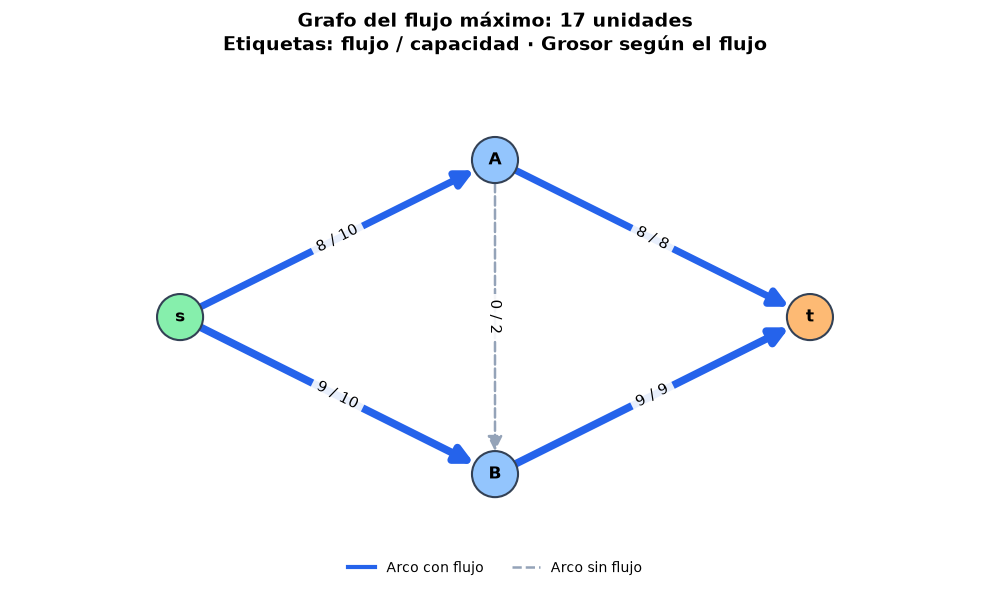

In [1]:
import pulp
import networkx as nx
# Importa las herramientas para dibujar el grafo del flujo máximo.
import matplotlib.pyplot as plt
# Permite crear los símbolos de la leyenda.
from matplotlib.lines import Line2D

# 1. Definición del grafo y capacidades
capacidades = {
    ('s', 'A'): 10,
    ('s', 'B'): 10,
    ('A', 'B'): 2,
    ('A', 't'): 8,
    ('B', 't'): 9
}
arcos = list(capacidades.keys())

# 2. Formulación PL con PuLP
modelo = pulp.LpProblem("Flujo_Maximo_Red", pulp.LpMaximize)

# Variables de flujo (Continuas >= 0, acotadas por la capacidad)
f = {e: pulp.LpVariable(f"f_{e[0]}_{e[1]}", lowBound=0, upBound=capacidades[e], cat='Continuous') for e in arcos}
F = pulp.LpVariable("Flujo_Total_F", lowBound=0, cat='Continuous')

# Función Objetivo
modelo += F, "Maximizar_Flujo_Neto"

# Restricciones de Conservación de Flujo
# Balance en la fuente s
modelo += (f[('s', 'A')] + f[('s', 'B')] == F), "Balance_Nodo_s"

# Conservación en nodos intermedios
modelo += (f[('s', 'A')] - f[('A', 'B')] - f[('A', 't')] == 0), "Conservacion_Nodo_A"
modelo += (f[('s', 'B')] + f[('A', 'B')] - f[('B', 't')] == 0), "Conservacion_Nodo_B"

# Balance en el sumidero t
modelo += (f[('A', 't')] + f[('B', 't')] == F), "Balance_Nodo_t"

# 3. Resolver
modelo.solve(pulp.PULP_CBC_CMD(msg=0))

# Comprueba que haya una solución óptima antes de consultar o graficar los flujos.
if modelo.status != pulp.LpStatusOptimal:
    raise RuntimeError("El modelo no tiene una solución óptima; revisa las capacidades.")

print("=" * 50)
print(f"ESTADO DE LA SOLUCIÓN: {pulp.LpStatus[modelo.status]}")
print(f"Flujo Máximo Óptimo F*: {pulp.value(F):.1f}")
print("=" * 50)
for e in arcos:
    print(f"Arco {e[0]} -> {e[1]}: Flujo = {f[e].varValue:4.1f} | Capacidad = {capacidades[e]:4.1f}")

# Construye el grafo dirigido usando las mismas capacidades y variables del modelo.
G = nx.DiGraph()
# Guarda en cada arco la capacidad y el flujo calculado por PuLP.
for u, v in arcos:
    G.add_edge(u, v, capacity=capacidades[(u, v)], flow=f[(u, v)].varValue)

# Fija las posiciones de los nodos para distinguir la fuente, los intermedios y el sumidero.
pos = {'s': (0, 1), 'A': (1, 2), 'B': (1, 0), 't': (2, 1)}
# Crea las etiquetas directamente con los valores resueltos y las capacidades del modelo.
etiquetas_arcos = {(u, v): f"{f[(u, v)].varValue:g} / {capacidades[(u, v)]:g}"
                   for u, v in arcos}
# Usa una tolerancia para distinguir flujos positivos de pequeños errores de redondeo.
tolerancia = 1e-7
# Identifica los arcos utilizados por la solución óptima.
arcos_con_flujo = [e for e in arcos if f[e].varValue > tolerancia]
# Mantiene visibles los arcos que no transportan flujo.
arcos_sin_flujo = [e for e in arcos if e not in arcos_con_flujo]
# Escala el grosor de las flechas según el mayor flujo de la solución.
escala_flujo = max([f[e].varValue for e in arcos] + [tolerancia])
# Asigna mayor grosor a los arcos que transportan más flujo.
grosores = [1.5 + 4 * f[e].varValue / escala_flujo for e in arcos_con_flujo]
# Distingue la fuente en verde, el sumidero en naranja y los nodos intermedios en azul.
colores_nodos = ['#86efac' if nodo == 's' else '#fdba74' if nodo == 't'
                 else '#93c5fd' for nodo in G.nodes]

# Crea la figura que se mostrará en la salida de esta misma celda.
fig, ax = plt.subplots(figsize=(10, 6))
# Dibuja los nodos con sus colores y bordes.
nx.draw_networkx_nodes(
    G, pos, ax=ax, node_size=1100, node_color=colores_nodos,
    edgecolors='#334155', linewidths=1.5)
# Dibuja en azul los arcos que transportan flujo, respetando su dirección.
nx.draw_networkx_edges(
    G, pos, ax=ax, edgelist=arcos_con_flujo, edge_color='#2563eb',
    width=grosores, arrowstyle='-|>', arrowsize=25, node_size=1100)
# Dibuja en gris discontinuo los arcos sin flujo.
nx.draw_networkx_edges(
    G, pos, ax=ax, edgelist=arcos_sin_flujo, edge_color='#94a3b8',
    style='dashed', width=1.8, arrowstyle='-|>', arrowsize=22, node_size=1100)
# Escribe los nombres de los nodos.
nx.draw_networkx_labels(G, pos, ax=ax, font_size=12, font_weight='bold')
# Muestra en cada arco la etiqueta flujo / capacidad.
nx.draw_networkx_edge_labels(
    G, pos, ax=ax, edge_labels=etiquetas_arcos, font_size=11,
    bbox=dict(facecolor='white', edgecolor='none', alpha=0.9))
# Obtiene el valor del título desde F, sin fijar manualmente el resultado.
ax.set_title(
    f"Grafo del flujo máximo: {pulp.value(F):g} unidades\n"
    "Etiquetas: flujo / capacidad · Grosor según el flujo",
    fontsize=14, fontweight='bold', pad=18)
ax.margins(0.20)
ax.axis('off')
# Explica los estilos de los arcos.
ax.legend(handles=[
    Line2D([], [], color='#2563eb', linewidth=3, label='Arco con flujo'),
    Line2D([], [], color='#94a3b8', linewidth=1.8, linestyle='--', label='Arco sin flujo'),
], loc='lower center', bbox_to_anchor=(0.5, -0.06), ncol=2, frameon=False)
# Ajusta el espacio de la figura para mostrar completos el título y la leyenda.
fig.tight_layout()
# Genera la salida gráfica al ejecutar la celda que resuelve el modelo.
plt.show()
